# 🎓 Planificador de estudio personalizado — sistema multi-agente con LangGraph + Groq

**Hackathon 7 · Semana 9 · Implementación de un sistema multi-agente con Groq**

| | |
|---|---|
| **Caso** | Planificador de estudio personalizado — *«Camacho quiere egresar»* |
| **Integrantes** | Juan Castro (expositor) · ✏️ Integrante 2 · ✏️ Integrante 3 · ✏️ Integrante 4 |
| **Fecha de entrega / exposición** | 14 de octubre de 2026 |
| **Stack** | Python · LangGraph (orquestación) · LangChain (`create_agent`, tools) · Groq (LLM) · Ollama (desarrollo local) |

**Contenido**
1. Introducción del caso · 2. Diseño de agentes · 3. Diseño del flujo de orquestación · 4. Implementación con Groq ·
5. Resultados intermedios · 6. Decisión final · 7. Evaluación crítica · Anexo: checklist de la demo en vivo

> ✏️ **Para el equipo:** los bloques con este icono son borradores. Reescríbanlos con sus palabras y borren la nota:
> la rúbrica premia que el equipo *defienda* sus decisiones de diseño, no que el texto sea perfecto.

## 6.2 Introducción del caso

**¿Cuál es el problema?** Un estudiante en su último tramo de la carrera (*«Camacho quiere egresar»*) lleva varios
cursos a la vez, cada uno con distinta dificultad, créditos y fecha de próxima evaluación, además de prácticas o
trabajo. Distribuir a mano sus horas libres de la semana suele terminar en sobrecarga o en descuidar justo el curso
que más pesa para egresar.

**¿Por qué es importante?** Egresar depende de aprobar los cursos que faltan; el recurso escaso es el tiempo semanal,
no la voluntad. Un mal reparto de ese tiempo tiene costo académico directo (desaprobar) y personal (agotamiento).

**¿Qué decisión se busca apoyar?** *¿Cuántas horas dedicar a cada curso, qué día y de qué forma, esta semana?*
El sistema recomienda **un plan semanal** y explica por qué es mejor que las alternativas.

**¿Quién usará el sistema?** Estudiantes de últimos ciclos y, como segundo usuario, tutores o asesores académicos que
quieran revisar la propuesta.

**¿Qué impacto tendría?** Planes realistas (que respetan la disponibilidad real), balanceados y alineados con las
prioridades del estudiante, con riesgos explícitos. La decisión final siempre la valida una persona.

> ✏️ Ajusten el contexto a la realidad del equipo (carrera, ciclo, tipo de restricciones reales).

## 6.3 Diseño de agentes

El sistema acepta un **prompt inicial con 5 inputs** (el enunciado pide entre 2 y 5): `cursos`, `disponibilidad`,
`prioridades`, `restricciones` y `meta`. Solo `cursos` y `disponibilidad` son obligatorios; los otros tres pueden
faltar y el sistema debe declararlo como supuesto (ver sección 6.8).

| Agente | Rol | Objetivo | Recibe | Produce | Tool |
|---|---|---|---|---|---|
| **Analista del estudiante** | Experto en análisis académico | Entender contexto, restricciones y prioridades | Prompt inicial (5 inputs) | Resumen estructurado del problema | `calcular_horas_requeridas` |
| **Planificador** | Diseñador de planes de estudio | Generar alternativas realistas | Perfil + análisis (+ feedback si hay revisión) | 2–3 planes semanales (JSON validado con Pydantic) | — |
| **Evaluador** | Evaluador de carga | Comparar los planes | Planes generados | Comparación con ventajas/desventajas + métricas | `evaluar_plan` |
| **Decisor** | Asesor académico | Recomendar el mejor plan | Análisis + planes + evaluación + ranking ponderado | Decisión final justificada (JSON) | — |

**¿Por qué 4 agentes?**
- *Analista* separado: convierte datos crudos en un diagnóstico (horas requeridas vs. disponibles) antes de planificar.
- *Planificador* y *Evaluador* separados: quien genera una solución no debería juzgarla (evita auto-sesgo) y el
  evaluador puede ser más estricto con otro prompt y otra temperatura.
- *Decisor* separado: integra todo y justifica; es el único responsable de la respuesta final.
- Un 5.º agente (p. ej. «monitor de seguimiento») no aportaría un rol nuevo dentro del alcance de una semana.

**¿Por qué tools?** Los LLM calculan mal. Por eso los números (horas requeridas, horas por día, sobrecarga,
balance, cobertura) salen de **funciones Python deterministas** que el agente invoca; el LLM interpreta y razona.
- `calcular_horas_requeridas` → la usa el **Analista**.
- `evaluar_plan` → la usa el **Evaluador**, una vez por plan.

> ✏️ Justifiquen con sus palabras la cantidad de agentes y qué agente usa qué tool.

## 6.4 Diseño del flujo de orquestación

- **Orden de ejecución:** Analista → Planificador → Evaluador → (¿hay un plan factible?) → Decisor.
- **Datos que pasan de un agente a otro:** prompt inicial → *resumen estructurado* → *planes en JSON* →
  *comparación + métricas de la tool* → *decisión final*. Todo vive en un **estado compartido** del grafo (LangGraph).
- **Tipo de flujo:** **secuencial con una rama condicional**. Si ningún plan cumple las restricciones duras
  (según la tool `evaluar_plan`), el flujo vuelve **una sola vez** al Planificador con el feedback de las violaciones
  (`MAX_REVISIONES = 1`, para no gastar cuota). Si sigue sin haber plan factible, el Decisor lo declara como riesgo.
- **Responsable de integrar la respuesta final:** el **Decisor**.

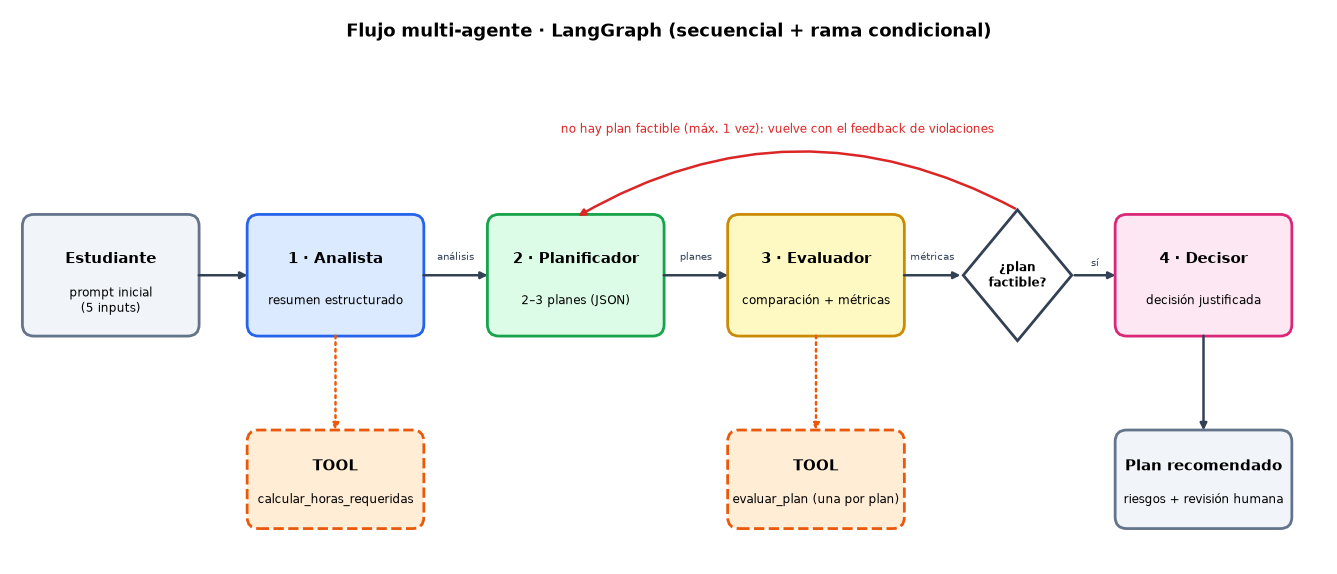

In [32]:
# Diagrama del flujo multi-agente (matplotlib, funciona sin internet). Se guarda en evidencias/diagrama_flujo.png
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Polygon


def dibujar_flujo(ruta="evidencias/diagrama_flujo.png"):
    fig, ax = plt.subplots(figsize=(17, 7.2))
    ax.set_xlim(0, 17)
    ax.set_ylim(0, 7.2)
    ax.axis("off")

    def caja(x, y, w, h, titulo, sub, fondo, borde, discontinua=False):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04,rounding_size=0.15",
                                    fc=fondo, ec=borde, lw=2, ls="--" if discontinua else "-"))
        ax.text(x + w / 2, y + h * 0.64, titulo, ha="center", va="center", fontsize=11, fontweight="bold")
        ax.text(x + w / 2, y + h * 0.28, sub, ha="center", va="center", fontsize=8.5)

    def flecha(p1, p2, texto="", color="#334155", estilo="-", curva=0.0, dy=0.2):
        ax.annotate("", xy=p2, xytext=p1, arrowprops=dict(arrowstyle="-|>", lw=1.8, color=color, ls=estilo,
                                                          connectionstyle=f"arc3,rad={curva}"))
        if texto:
            ax.text((p1[0] + p2[0]) / 2, (p1[1] + p2[1]) / 2 + dy, texto, ha="center", fontsize=7.5, color=color)

    Y, H, W = 3.0, 1.5, 2.2
    caja(0.2, Y, W, H, "Estudiante", "prompt inicial\n(5 inputs)", "#f1f5f9", "#64748b")
    caja(3.1, Y, W, H, "1 · Analista", "resumen estructurado", "#dbeafe", "#2563eb")
    caja(6.2, Y, W, H, "2 · Planificador", "2–3 planes (JSON)", "#dcfce7", "#16a34a")
    caja(9.3, Y, W, H, "3 · Evaluador", "comparación + métricas", "#fef9c3", "#ca8a04")
    caja(14.3, Y, W, H, "4 · Decisor", "decisión justificada", "#fce7f3", "#db2777")
    # decisión condicional
    cx, cy = 13.0, Y + H / 2
    ax.add_patch(Polygon([(cx, cy + 0.85), (cx + 0.7, cy), (cx, cy - 0.85), (cx - 0.7, cy)],
                         closed=True, fc="#fff", ec="#334155", lw=2))
    ax.text(cx, cy, "¿plan\nfactible?", ha="center", va="center", fontsize=8.5, fontweight="bold")
    # tools (sin emoji: la fuente por defecto de matplotlib no lo dibuja)
    caja(3.1, 0.5, W, 1.2, "TOOL", "calcular_horas_requeridas", "#ffedd5", "#ea580c", True)
    caja(9.3, 0.5, W, 1.2, "TOOL", "evaluar_plan (una por plan)", "#ffedd5", "#ea580c", True)
    # salida
    caja(14.3, 0.5, W, 1.2, "Plan recomendado", "riesgos + revisión humana", "#f1f5f9", "#64748b")

    my = Y + H / 2
    flecha((0.2 + W, my), (3.1, my))
    flecha((3.1 + W, my), (6.2, my), "análisis")
    flecha((6.2 + W, my), (9.3, my), "planes")
    flecha((9.3 + W, my), (cx - 0.7, my), "métricas")
    flecha((cx + 0.7, my), (14.3, my), "sí", dy=0.12)
    flecha((cx, cy + 0.85), (6.2 + W / 2, Y + H), color="#dc2626", curva=0.28)
    ax.text(9.9, 5.6, "no hay plan factible (máx. 1 vez): vuelve con el feedback de violaciones",
            ha="center", fontsize=8.5, color="#dc2626")
    flecha((3.1 + W / 2, Y), (3.1 + W / 2, 1.7), color="#ea580c", estilo=":")
    flecha((9.3 + W / 2, Y), (9.3 + W / 2, 1.7), color="#ea580c", estilo=":")
    flecha((14.3 + W / 2, Y), (14.3 + W / 2, 1.7))
    ax.text(8.5, 6.85, "Flujo multi-agente · LangGraph (secuencial + rama condicional)", ha="center",
            fontsize=13, fontweight="bold")
    Path(ruta).parent.mkdir(exist_ok=True)
    fig.savefig(ruta, dpi=150, bbox_inches="tight")
    plt.show()


dibujar_flujo()

## 6.5 Implementación con Groq

### 6.5.1 Configuración del entorno
Instalación (una vez): `pip install -r requirements.txt`, o descomenten la línea de abajo.

**Gestión de API keys** (parte de la rúbrica de la demo en vivo):
- Las keys van en un archivo `.env` (nunca en el notebook ni en el repositorio): `GROQ_API_KEYS=gsk_aaa,gsk_bbb`.
- Cada integrante puede crear su cuenta de Groq con el correo UTEC y aportar una key. Cada agente usa una key
  distinta (*round-robin*): el límite de tokens por minuto se reparte entre keys.
- Si Groq responde `429`, el SDK reintenta respetando `retry-after`; si igual falla, se cae a un modelo de respaldo
  con otra key (y opcionalmente a Ollama local).
- Cada agente puede usar un modelo distinto: el límite de tokens por minuto de Groq es **por modelo**.
- `verificar_conexion()` prueba cada key/modelo antes de la demo, y la telemetría muestra los tokens consumidos.

Para desarrollar sin gastar cuota: `BACKEND=ollama` en el `.env` (requiere Ollama instalado y un modelo con tools,
p. ej. `ollama pull qwen3:8b`).

In [33]:
# %pip install -q langchain langgraph langchain-groq langchain-ollama python-dotenv pydantic matplotlib

import getpass
import json
import os
import re
import statistics
import time
import unicodedata
from datetime import datetime
from pathlib import Path
from typing import Literal, Optional, TypedDict

from dotenv import load_dotenv
from IPython.display import Markdown, display
from langchain.agents import AgentState, create_agent
from langchain.agents.middleware import ModelCallLimitMiddleware, ModelFallbackMiddleware
from langchain.tools import ToolRuntime, tool
from langchain_core.callbacks import BaseCallbackHandler
from langchain_core.messages import HumanMessage, SystemMessage, ToolMessage
from langchain_core.runnables import RunnableConfig
from langchain_groq import ChatGroq
from langchain_ollama import ChatOllama
from langgraph.graph import END, START, StateGraph
from pydantic import BaseModel, Field

load_dotenv()  # lee .env (GROQ_API_KEYS, BACKEND, OLLAMA_MODEL)

# ---------------------------------------------------------------- configuración general
BACKEND = os.getenv("BACKEND", "groq").lower()  # "groq" (demo en vivo) | "ollama" (desarrollo local)
OLLAMA_MODEL = os.getenv("OLLAMA_MODEL", "qwen3:8b")
RESPALDO_OLLAMA = False  # True: si Groq falla, intentar con Ollama local como último recurso
MODO_INTERACTIVO = os.getenv("MODO_INTERACTIVO", "1") == "1"  # False: usa el perfil de ejemplo sin preguntar

ORDEN_AGENTES = ["analista", "planificador", "evaluador", "decisor"]

# ✏️ Selección del modelo (6.5): modelo por agente. Se probó con una cuenta real de Groq (oct-2026): los modelos de
# chat disponibles eran openai/gpt-oss-120b, openai/gpt-oss-20b y qwen/qwen3.8-27b (los Llama ya no estaban). Los
# modelos cambian seguido: revisen con client.models.list() o en console.groq.com/docs/models.
#  - planificador → gpt-oss-120b: el que más razona; genera los planes en JSON.
#  - evaluador → qwen3.8-27b: soporta llamadas paralelas a tools (evalúa los 3 planes en una sola ronda).
#  - analista y decisor → gpt-oss-20b: tareas más acotadas; además reparten el cupo de tokens, que Groq limita POR MODELO.
MODELO_POR_AGENTE = {
    "analista": "openai/gpt-oss-20b",
    "planificador": "openai/gpt-oss-120b",
    "evaluador": "qwen/qwen3.8-27b",
    "decisor": "openai/gpt-oss-20b",
}
MODELOS_RESPALDO = ["openai/gpt-oss-20b", "qwen/qwen3.8-27b"]  # si el principal falla (se omite el que ya es el principal)
MAX_TOKENS = {"analista": 1200, "planificador": 3500, "evaluador": 1200, "decisor": 1800}  # tope de salida por agente
TEMPERATURA = {"analista": 0.2, "planificador": 0.5, "evaluador": 0.1, "decisor": 0.2}

MAX_REVISIONES = 1  # veces que el Evaluador puede devolver el flujo al Planificador

# ✏️ Ponderación de criterios (deben sumar 1). Defiendan por qué pesan así.
PESOS_CRITERIOS = {
    "factibilidad": 0.35,  # ¿respeta disponibilidad por día y límites de sesión?
    "cobertura_prioridades": 0.30,  # ¿cubre las horas requeridas, sobre todo de cursos prioritarios?
    "balance_carga": 0.20,  # ¿reparte la carga de forma pareja entre los días?
    "riesgo_sobrecarga": 0.15,  # ¿evita usar casi todo el tiempo libre (riesgo de agotamiento)?
}
assert abs(sum(PESOS_CRITERIOS.values()) - 1) < 1e-9, "Los pesos deben sumar 1"

# ✏️ Parámetros de las tools (fórmulas que el equipo debe poder explicar)
HORAS_POR_CREDITO = 1.5  # horas de estudio autónomo por semana por crédito
FACTOR_DIFICULTAD = {1: 0.8, 2: 0.9, 3: 1.0, 4: 1.25, 5: 1.5}
FACTOR_PRIORIDAD = 1.2  # multiplicador si el curso aparece en las prioridades del estudiante
MAX_HORAS_SESION = 3.0  # una sesión de estudio no debería pasar de este tope
DIAS = ["L", "M", "X", "J", "V", "S", "D"]
NOMBRE_DIA = {"L": "Lunes", "M": "Martes", "X": "Miércoles", "J": "Jueves", "V": "Viernes", "S": "Sábado", "D": "Domingo"}


def factor_urgencia(dias_a_evaluacion):
    """Cuanto más cerca la evaluación, más horas requiere el curso."""
    if dias_a_evaluacion is None:
        return 1.0
    if dias_a_evaluacion <= 3:
        return 1.5
    if dias_a_evaluacion <= 7:
        return 1.3
    if dias_a_evaluacion <= 14:
        return 1.15
    return 1.0


# ---------------------------------------------------------------- API keys y modelos
def cargar_keys_groq():
    crudo = os.getenv("GROQ_API_KEYS") or os.getenv("GROQ_API_KEY") or ""
    keys = [k.strip() for k in crudo.split(",") if k.strip()]
    if not keys:
        keys = [getpass.getpass("Pega tu GROQ_API_KEY (no se guarda en el notebook): ").strip()]
    return keys


KEYS_GROQ = cargar_keys_groq() if BACKEND == "groq" else []
print(f"Backend: {BACKEND} | keys de Groq cargadas: {len(KEYS_GROQ)} "
      f"({', '.join('…' + k[-4:] for k in KEYS_GROQ) or 'ninguna'})")


def indice_key(agente):
    """Qué key usa un agente. El cupo de tokens de Groq es por modelo y por cuenta, así que los agentes que
    comparten modelo se reparten entre keys distintas (si hay más de una)."""
    mismos = [a for a in ORDEN_AGENTES if MODELO_POR_AGENTE[a] == MODELO_POR_AGENTE[agente]]
    return mismos.index(agente)


def crear_llm(agente, modelo=None, desplazamiento=0):
    """Crea el chat model de un agente. `desplazamiento` rota la key (para los modelos de respaldo)."""
    if BACKEND == "ollama":
        return ChatOllama(model=OLLAMA_MODEL, temperature=TEMPERATURA[agente], num_predict=MAX_TOKENS[agente])
    modelo = modelo or MODELO_POR_AGENTE[agente]
    key = KEYS_GROQ[(indice_key(agente) + desplazamiento) % len(KEYS_GROQ)]
    extra = {"reasoning_effort": "low"} if modelo.startswith("openai/gpt-oss") else {}
    return ChatGroq(model=modelo, api_key=key, temperature=TEMPERATURA[agente], max_tokens=MAX_TOKENS[agente],
                    max_retries=4, timeout=90, **extra)


def modelos_del_agente(agente):
    """Devuelve (modelo principal, [modelos de respaldo]) para un agente."""
    principal = crear_llm(agente)
    respaldos = []
    if BACKEND == "groq":
        alternos = [m for m in MODELOS_RESPALDO if m != MODELO_POR_AGENTE[agente]]
        respaldos += [crear_llm(agente, modelo=m, desplazamiento=i + 1) for i, m in enumerate(alternos)]
        if RESPALDO_OLLAMA:
            respaldos.append(ChatOllama(model=OLLAMA_MODEL, temperature=TEMPERATURA[agente]))
    return principal, respaldos


def cadena_estructurada(agente, esquema):
    """Agente sin tools que responde con un objeto Pydantic (con respaldo automático si falla)."""
    principal, respaldos = modelos_del_agente(agente)
    cadena = principal.with_structured_output(esquema)
    if respaldos:
        cadena = cadena.with_fallbacks([r.with_structured_output(esquema) for r in respaldos])
    return cadena


def verificar_conexion():
    """Prueba cada agente (modelo + key) con una llamada mínima. Ejecutar ANTES de la demo."""
    for agente in ORDEN_AGENTES:
        llm = crear_llm(agente)
        key = f"…{KEYS_GROQ[indice_key(agente) % len(KEYS_GROQ)][-4:]}" if KEYS_GROQ else "local"
        t0 = time.time()
        try:
            llm.invoke("Responde solo: OK")
            print(f"✅ {agente:<13} modelo={MODELO_POR_AGENTE[agente] if BACKEND == 'groq' else OLLAMA_MODEL:<26} "
                  f"key={key} {time.time() - t0:.1f}s")
        except Exception as e:  # noqa: BLE001 - queremos ver cualquier fallo antes de la demo
            print(f"❌ {agente:<13} {type(e).__name__}: {str(e)[:120]}")


# verificar_conexion()  # ← descomentar para probar keys/modelos (gasta ~4 llamadas mínimas)

Backend: groq | keys de Groq cargadas: 1 (…c99R)


### 6.5.2 Entradas, estado y esquemas de datos
Los 5 inputs del prompt inicial se validan con Pydantic. Lo que no se puede inferir se completa con valores por
defecto **y se registra como supuesto** (para que el Analista lo declare).

In [34]:
class Curso(BaseModel):
    nombre: str
    dificultad: int = Field(3, ge=1, le=5)
    creditos: int = Field(3, ge=1, le=8)
    dias_a_evaluacion: Optional[int] = Field(None, ge=0)


class Perfil(BaseModel):
    cursos: list[Curso]
    disponibilidad: dict[str, float]  # horas libres por día: {"L": 3, "M": 2, ...}
    prioridades: list[str] = []
    restricciones: str = ""
    meta: str = ""
    supuestos: list[str] = []  # datos faltantes que se completaron con valores por defecto


class Sesion(BaseModel):
    dia: Literal["L", "M", "X", "J", "V", "S", "D"]
    curso: str = Field(description="Nombre EXACTO de un curso del perfil")
    horas: float = Field(gt=0, le=6, description="Horas de la sesión (múltiplos de 0.5)")
    actividad: str = Field(description="Tarea concreta, máx. 6 palabras (p. ej. 'ejercicios de regresión'); "
                                       "no repitas el nombre del curso")


class PlanSemanal(BaseModel):
    id: str = Field(description="A, B o C")
    nombre: str = Field(description="Nombre corto del enfoque, sin la palabra 'Plan' ni la letra (p. ej. 'Críticos primero')")
    estrategia: str = Field(description="Idea central del plan en una frase")
    sesiones: list[Sesion]


class Planes(BaseModel):
    planes: list[PlanSemanal] = Field(min_length=2, max_length=3)


class Decision(BaseModel):
    plan_elegido: str = Field(description="id del plan elegido: A, B o C")
    justificacion: str
    criterios_clave: list[str] = Field(description="Criterios que más pesaron en la decisión")
    riesgos: list[str] = Field(description="Riesgos que permanecen")
    revision_humana: list[str] = Field(description="Qué debe revisar una persona antes de aplicar el plan")
    recomendaciones: list[str]


class EstadoPlan(TypedDict, total=False):
    """Estado compartido del grafo: lo que cada agente lee y escribe."""
    perfil: dict
    prompt_inicial: str
    analisis: str
    planes: list
    evaluacion: str
    metricas: dict
    ranking: list
    feedback: str
    revisiones: int
    decision: dict


class EstadoConPerfil(AgentState):  # estado interno del Analista (las tools leen `perfil`)
    perfil: dict


class EstadoConPlanes(AgentState):  # estado interno del Evaluador (las tools leen `perfil` y `planes`)
    perfil: dict
    planes: list

### 6.5.3 Tools (funciones deterministas que los agentes invocan)
- `calcular_horas_requeridas` → **Analista**: horas semanales por curso = créditos × `HORAS_POR_CREDITO` ×
  factor de dificultad × factor de urgencia (evaluación cercana) × factor de prioridad.
- `evaluar_plan` → **Evaluador**: revisa un plan contra la disponibilidad real y devuelve métricas y puntajes 0–100
  por criterio, el puntaje total ponderado (`PESOS_CRITERIOS`) y si el plan es **factible**.

El modelo solo pasa el `plan_id`; la tool lee el plan y el perfil del estado (no hay que copiar JSON largos,
lo que ahorra tokens y evita errores de transcripción).

In [35]:
def _norm(texto):
    return unicodedata.normalize("NFKD", texto.lower()).encode("ascii", "ignore").decode().strip()


def es_prioritario(nombre_curso, prioridades):
    n = _norm(nombre_curso)
    return any(_norm(p) and (n in _norm(p) or _norm(p) in n) for p in prioridades)


def horas_requeridas(curso, prioridades):
    f_dif = FACTOR_DIFICULTAD[curso["dificultad"]]
    f_urg = factor_urgencia(curso.get("dias_a_evaluacion"))
    f_pri = FACTOR_PRIORIDAD if es_prioritario(curso["nombre"], prioridades) else 1.0
    horas = curso["creditos"] * HORAS_POR_CREDITO * f_dif * f_urg * f_pri
    return round(horas, 1), {"dificultad": f_dif, "urgencia": f_urg, "prioridad": f_pri}


def canonizar_curso(nombre, perfil):
    """Empareja el nombre que escribió el LLM con el nombre exacto del perfil (tolera mayúsculas/tildes)."""
    n = _norm(nombre)
    for c in perfil["cursos"]:
        if _norm(c["nombre"]) == n:
            return c["nombre"]
    for c in perfil["cursos"]:
        if n and (n in _norm(c["nombre"]) or _norm(c["nombre"]) in n):
            return c["nombre"]
    return None


def calcular_metricas_plan(plan, perfil):
    """Evaluación determinista de un plan. Es la lógica detrás de la tool `evaluar_plan`."""
    disp = {d: float(perfil["disponibilidad"].get(d, 0)) for d in DIAS}
    req = {c["nombre"]: horas_requeridas(c, perfil["prioridades"])[0] for c in perfil["cursos"]}
    horas_dia = {d: 0.0 for d in DIAS}
    asignadas = {n: 0.0 for n in req}
    violaciones = []
    for s in plan["sesiones"]:
        nombre = canonizar_curso(s["curso"], perfil)
        if nombre is None:
            violaciones.append(f"Sesión con un curso que no existe en el perfil: '{s['curso']}'")
            continue
        horas_dia[s["dia"]] += float(s["horas"])
        asignadas[nombre] += float(s["horas"])
        if s["horas"] > MAX_HORAS_SESION:
            violaciones.append(f"Sesión de {s['horas']} h de {nombre} el {NOMBRE_DIA[s['dia']]} "
                               f"supera el máximo de {MAX_HORAS_SESION} h")
    for d in DIAS:
        if horas_dia[d] > disp[d] + 1e-6:
            violaciones.append(f"{NOMBRE_DIA[d]}: {horas_dia[d]:g} h asignadas pero solo hay {disp[d]:g} h disponibles")

    dias_disp = [d for d in DIAS if disp[d] > 0]
    utilizacion = [horas_dia[d] / disp[d] for d in dias_disp]
    util_media = statistics.mean(utilizacion) if utilizacion else 0.0
    dias_al_limite = sum(1 for u in utilizacion if u > 0.9)
    # Balance: dispersión de la utilización solo en los días que se estudia. Un día de descanso es legítimo:
    # solo se penaliza estudiar en menos de (días disponibles - 1) días (concentrar todo en pocos días).
    usados = [horas_dia[d] / disp[d] for d in dias_disp if horas_dia[d] > 0]
    desviacion = statistics.pstdev(usados) if len(usados) > 1 else 0.0
    factor_dias = min(1.0, len(usados) / max(1, len(dias_disp) - 1))

    cobertura = {n: (min(1.0, asignadas[n] / req[n]) if req[n] > 0 else 1.0) for n in req}
    prioritarios = [n for n in req if es_prioritario(n, perfil["prioridades"])]
    cob_prior = statistics.mean(cobertura[n] for n in (prioritarios or req))
    cob_total = statistics.mean(cobertura.values())

    puntajes = {
        "factibilidad": max(0, 100 - 25 * len(violaciones)),
        "cobertura_prioridades": round(100 * (0.7 * cob_prior + 0.3 * cob_total)),
        "balance_carga": round(100 * max(0.0, 1 - desviacion / 0.5) * factor_dias),
        "riesgo_sobrecarga": round(max(0.0, 100 - 100 * max(0.0, util_media - 0.75) / 0.25 - 10 * dias_al_limite)),
    }
    total = round(sum(PESOS_CRITERIOS[k] * v for k, v in puntajes.items()), 1)
    return {
        "plan_id": plan["id"],
        "factible": not violaciones,
        "horas_totales": round(sum(horas_dia.values()), 1),
        "horas_por_dia": {d: round(h, 1) for d, h in horas_dia.items()},
        "utilizacion_media": round(util_media, 2),
        "cobertura_por_curso": {n: round(c, 2) for n, c in cobertura.items()},
        "violaciones": violaciones,
        "puntajes": puntajes,
        "puntaje_total": total,
    }


@tool
def calcular_horas_requeridas(runtime: ToolRuntime) -> str:
    """Calcula las horas semanales de estudio que requiere cada curso del estudiante (créditos, dificultad,
    cercanía de la evaluación y prioridad) y las compara con las horas libres de la semana.
    Úsala siempre antes de redactar el análisis. No recibe argumentos."""
    perfil = runtime.state["perfil"]
    cursos = []
    for c in perfil["cursos"]:
        horas, factores = horas_requeridas(c, perfil["prioridades"])
        cursos.append({"curso": c["nombre"], "horas_requeridas": horas, "factores": factores})
    total_req = round(sum(c["horas_requeridas"] for c in cursos), 1)
    total_disp = round(sum(float(v) for v in perfil["disponibilidad"].values()), 1)
    return json.dumps({
        "cursos": cursos,
        "total_requerido": total_req,
        "total_disponible": total_disp,
        "deficit_horas": round(max(0.0, total_req - total_disp), 1),
        "alcanza_el_tiempo": total_req <= total_disp,
    }, ensure_ascii=False)


@tool
def evaluar_plan(plan_id: str, runtime: ToolRuntime) -> str:
    """Evalúa un plan semanal (id: 'A', 'B' o 'C') contra la disponibilidad real del estudiante. Devuelve horas por
    día, cobertura por curso, violaciones de restricciones, puntajes 0-100 por criterio, puntaje total ponderado y
    si el plan es factible. Debes llamarla una vez por cada plan."""
    estado = runtime.state
    plan = next((p for p in estado["planes"] if p["id"] == plan_id.strip().upper()), None)
    if plan is None:
        ids = [p["id"] for p in estado["planes"]]
        return json.dumps({"error": f"plan_id '{plan_id}' no existe. Ids válidos: {ids}"}, ensure_ascii=False)
    return json.dumps(calcular_metricas_plan(plan, estado["perfil"]), ensure_ascii=False)

### 6.5.4 Prompts de los agentes
> ✏️ **Esta es la parte que la rúbrica mira con lupa («implementación personalizada y metódica de las
> instrucciones de cada agente»).** Léanlos, pruébenlos, cámbienlos con su criterio y anoten por qué.

In [36]:
PROMPT_INICIAL = """Soy estudiante y quiero egresar. Necesito un plan semanal de estudio.
1) CURSOS (nombre; dificultad 1-5; créditos; días hasta la próxima evaluación):
{cursos}
2) DISPONIBILIDAD (horas libres por día):
{disponibilidad}
3) PRIORIDADES ACADÉMICAS (de mayor a menor):
{prioridades}
4) RESTRICCIONES:
{restricciones}
5) META:
{meta}
{supuestos}"""

PROMPT_ANALISTA = """Eres un analista académico. Recibes la solicitud de un estudiante que quiere egresar.

Pasos obligatorios:
1. Llama a la tool `calcular_horas_requeridas` para obtener las horas semanales que requiere cada curso. No estimes
   horas por tu cuenta: usa solo los números de la tool.
2. Redacta un resumen estructurado en Markdown, de máximo 250 palabras, con estas secciones:
   ## Cursos y dificultad (tabla con curso, dificultad, créditos, días a la evaluación, horas requeridas)
   ## Tiempo disponible vs. requerido (usa total_requerido, total_disponible y deficit_horas)
   ## Prioridades y restricciones
   ## Supuestos y datos faltantes (si no hay ninguno, escribe «ninguno»)
   ## Riesgos iniciales
No propongas el plan semanal: solo analiza."""

PROMPT_PLANIFICADOR = """Eres un planificador de estudio. Recibes el perfil del estudiante (JSON) y el análisis de un
analista. Genera 3 planes semanales alternativos (2 si el tiempo es muy escaso) con ESTRATEGIAS REALMENTE DISTINTAS,
que cambien cuántas horas se usan y cómo se reparten (no repitas el mismo reparto de horas por día en los tres):
 - Plan A (intensivo): prioriza los cursos críticos y las evaluaciones más cercanas; puede usar hasta el 100 % del
   tiempo libre de los días.
 - Plan B (con colchón): carga pareja entre los días usando como máximo el 80 % de las horas disponibles de cada día,
   para dejar margen ante imprevistos.
 - Plan C (bloques): sesiones más largas concentradas en los días con más tiempo libre y al menos 2 días ligeros.
Cada plan debe repartir las horas según lo que necesita cada curso (dificultad, créditos, cercanía de la evaluación).
Reglas duras (un plan que las rompa es inválido):
 - Las horas asignadas a un día NO pueden superar las horas disponibles de ese día (disponibilidad del perfil).
 - Ninguna sesión puede durar más de 3 horas; usa múltiplos de 0.5 h; máximo 3 sesiones por día.
 - Usa el nombre EXACTO de los cursos del perfil.
 - Respeta las restricciones del estudiante (por ejemplo, un día de descanso).
Si recibes FEEDBACK DE REVISIÓN, corrige exactamente esas violaciones en los nuevos planes."""

PROMPT_EVALUADOR = """Eres un evaluador académico especializado en carga de trabajo. Recibes los planes semanales
generados (con sus ids) y el perfil del estudiante.

Pasos obligatorios:
1. Llama a la tool `evaluar_plan` UNA VEZ POR CADA plan, con el id exacto (A, B, C), antes de responder.
2. Redacta en Markdown, de máximo 300 palabras, una comparación:
   - Una tabla con los puntajes que devolvió la tool (no inventes cifras).
   - Ventajas y desventajas de cada plan.
   - Qué planes violan restricciones y por qué.
   - Riesgo de sobrecarga y alineación con las prioridades del estudiante."""

PROMPT_DECISOR = """Eres un asesor académico. Recibes el análisis del estudiante, los planes, la evaluación comparativa
y un RANKING PONDERADO calculado por una tool con pesos fijos. Debes recomendar el mejor plan.
 - Elige un solo plan. Si te apartas del primer lugar del ranking, explica por qué.
 - justificacion: máximo 120 palabras, en términos del estudiante.
 - criterios_clave: los criterios que más pesaron en tu elección.
 - riesgos: los riesgos que permanecen aunque se aplique el plan.
 - revision_humana: qué debe verificar una persona antes de aplicar el plan (datos, fechas, restricciones reales).
 - recomendaciones: 3 consejos concretos y breves."""

### 6.5.5 Telemetría (evidencia en vivo de las tools, tokens y fallos)
Un *callback* de LangChain observa todas las llamadas: imprime un aviso **🔧** cada vez que un agente ejecuta una
tool (evidencia exigida en la demo) y acumula modelo, tokens y latencia por llamada.

In [37]:
class Telemetria(BaseCallbackHandler):
    def __init__(self):
        self.reset()

    def reset(self):
        self.agente_actual = "-"
        self.llamadas, self.tools, self.errores, self._t0 = [], [], [], {}

    def on_chat_model_start(self, serialized, messages, *, run_id, **kwargs):
        self._t0[run_id] = time.time()

    def on_llm_end(self, response, *, run_id, **kwargs):
        msg = getattr(response.generations[0][0], "message", None)
        uso = getattr(msg, "usage_metadata", None) or {}
        meta = getattr(msg, "response_metadata", None) or {}
        self.llamadas.append({
            "agente": self.agente_actual,
            "modelo": meta.get("model_name") or meta.get("model") or "?",
            "tokens_in": uso.get("input_tokens", 0),
            "tokens_out": uso.get("output_tokens", 0),
            "seg": round(time.time() - self._t0.pop(run_id, time.time()), 2),
        })

    def on_llm_error(self, error, *, run_id, **kwargs):
        self.errores.append({"agente": self.agente_actual, "error": type(error).__name__})
        print(f"   ⚠️  [{self.agente_actual}] {type(error).__name__} → reintento / modelo de respaldo")

    def on_tool_start(self, serialized, input_str, *, run_id, **kwargs):
        nombre = (serialized or {}).get("name") or kwargs.get("name") or "?"
        self.tools.append({"agente": self.agente_actual, "tool": nombre, "args": str(input_str)[:120], "resultado": ""})
        print(f"\n🔧 [{self.agente_actual.upper()}] ejecutó la TOOL → {nombre}({str(input_str)[:80]})")

    def on_tool_end(self, output, *, run_id, **kwargs):
        texto = getattr(output, "content", output)
        if self.tools:
            self.tools[-1]["resultado"] = str(texto)[:300]
        print(f"   ↳ resultado: {str(texto)[:160]}{'…' if len(str(texto)) > 160 else ''}")


TELE = Telemetria()

### 6.5.6 Agentes y nodos del grafo
- **Analista** y **Evaluador**: agentes *con tool* (`create_agent`), con tope de llamadas al modelo
  (`ModelCallLimitMiddleware`) para que un bucle de tools no consuma la cuota, y modelo de respaldo.
- **Planificador** y **Decisor**: agentes *sin tool* que devuelven un objeto Pydantic validado.

In [38]:
def crear_agente_con_tools(agente, prompt, tools, state_schema, tope_llamadas=6):
    principal, respaldos = modelos_del_agente(agente)
    middleware = [ModelCallLimitMiddleware(run_limit=tope_llamadas, exit_behavior="end")]
    if respaldos:
        middleware.insert(0, ModelFallbackMiddleware(*respaldos))
    return create_agent(model=principal, tools=tools, system_prompt=prompt, middleware=middleware,
                        state_schema=state_schema, name=agente)


AGENTE_ANALISTA = crear_agente_con_tools("analista", PROMPT_ANALISTA, [calcular_horas_requeridas], EstadoConPerfil)
AGENTE_EVALUADOR = crear_agente_con_tools("evaluador", PROMPT_EVALUADOR, [evaluar_plan], EstadoConPlanes)
CADENA_PLANIFICADOR = cadena_estructurada("planificador", Planes)
CADENA_DECISOR = cadena_estructurada("decisor", Decision)


def _texto(mensaje):
    contenido = mensaje.content
    if isinstance(contenido, list):
        contenido = "".join(b.get("text", "") if isinstance(b, dict) else str(b) for b in contenido)
    return re.sub(r"<think>.*?</think>", "", contenido, flags=re.S).strip()  # algunos modelos devuelven su razonamiento


def anunciar(agente):
    TELE.agente_actual = agente
    modelo = MODELO_POR_AGENTE[agente] if BACKEND == "groq" else OLLAMA_MODEL
    print(f"\n▶️  Agente «{agente}» trabajando… (modelo: {modelo})")


def resumen_plan(plan):
    por_dia = {}
    for s in plan["sesiones"]:
        por_dia.setdefault(s["dia"], []).append(f"{s['curso']} {s['horas']:g}h")
    return " | ".join(f"{d}: {', '.join(por_dia[d])}" for d in DIAS if d in por_dia)


def resumen_perfil(perfil):
    cursos = "; ".join(f"{c['nombre']} (dif {c['dificultad']}, {c['creditos']} cr, eval en {c['dias_a_evaluacion']} d)"
                       for c in perfil["cursos"])
    disp = " ".join(f"{d}={perfil['disponibilidad'].get(d, 0):g}" for d in DIAS)
    return f"Cursos: {cursos}\nDisponibilidad (h/día): {disp}\nPrioridades: {', '.join(perfil['prioridades']) or 'no indicadas'}\n" \
           f"Restricciones: {perfil['restricciones'] or 'no indicadas'}\nMeta: {perfil['meta'] or 'no indicada'}"


def nodo_analista(estado: EstadoPlan, config: RunnableConfig):
    anunciar("analista")
    res = AGENTE_ANALISTA.invoke({"messages": [HumanMessage(estado["prompt_inicial"])], "perfil": estado["perfil"]},
                                 config=config)
    return {"analisis": _texto(res["messages"][-1])}


def nodo_planificador(estado: EstadoPlan, config: RunnableConfig):
    anunciar("planificador")
    entrada = (f"PERFIL (JSON):\n{json.dumps(estado['perfil'], ensure_ascii=False)}\n\n"
               f"ANÁLISIS:\n{estado['analisis']}")
    es_revision = bool(estado.get("feedback"))
    if es_revision:
        entrada += f"\n\nFEEDBACK DE REVISIÓN (corrige esto):\n{estado['feedback']}"
        print("   🔁 revisión: el Evaluador devolvió el flujo con feedback de violaciones")
    salida = CADENA_PLANIFICADOR.invoke([SystemMessage(PROMPT_PLANIFICADOR), HumanMessage(entrada)], config=config)
    planes = [p.model_dump() for p in salida.planes]
    for i, p in enumerate(planes):
        p["id"] = "ABC"[i]  # ids deterministas, sin duplicados
    return {"planes": planes, "revisiones": estado.get("revisiones", 0) + (1 if es_revision else 0), "feedback": ""}


def construir_feedback(metricas):
    lineas = [f"Plan {pid}: {v}" for pid, m in metricas.items() for v in m["violaciones"][:4]]
    return "Ningún plan cumplió las restricciones duras. Corrige lo siguiente:\n" + "\n".join(lineas)


def nodo_evaluador(estado: EstadoPlan, config: RunnableConfig):
    anunciar("evaluador")
    descripcion = "\n".join(f"Plan {p['id']} — {p['nombre']}: {p['estrategia']}\n   {resumen_plan(p)}"
                            for p in estado["planes"])
    entrada = f"PERFIL:\n{resumen_perfil(estado['perfil'])}\n\nPLANES A EVALUAR:\n{descripcion}"
    res = AGENTE_EVALUADOR.invoke({"messages": [HumanMessage(entrada)], "planes": estado["planes"],
                                   "perfil": estado["perfil"]}, config=config)
    # Métricas que realmente devolvió la tool durante la conversación del agente
    metricas = {}
    for m in res["messages"]:
        if isinstance(m, ToolMessage) and m.name == "evaluar_plan":
            try:
                datos = json.loads(m.content)
                if "plan_id" in datos:
                    metricas[datos["plan_id"]] = datos
            except (json.JSONDecodeError, TypeError):
                pass
    for p in estado["planes"]:  # red de seguridad: si el agente olvidó un plan, se evalúa igual (y se avisa)
        if p["id"] not in metricas:
            print(f"   ⚠️  el Evaluador no llamó a la tool para el plan {p['id']}: se evalúa de forma determinista")
            metricas[p["id"]] = calcular_metricas_plan(p, estado["perfil"])
    ranking = sorted(metricas.values(), key=lambda m: (m["factible"], m["puntaje_total"]), reverse=True)
    hay_factible = any(m["factible"] for m in metricas.values())
    return {"evaluacion": _texto(res["messages"][-1]), "metricas": metricas, "ranking": ranking,
            "feedback": "" if hay_factible else construir_feedback(metricas)}


def decidir_siguiente(estado: EstadoPlan) -> Literal["planificador", "decisor"]:
    """Arista condicional: ¿hay al menos un plan factible? Si no, una revisión más (hasta MAX_REVISIONES)."""
    hay_factible = any(m["factible"] for m in estado["metricas"].values())
    if not hay_factible and estado.get("revisiones", 0) < MAX_REVISIONES:
        return "planificador"
    return "decisor"


def nodo_decisor(estado: EstadoPlan, config: RunnableConfig):
    anunciar("decisor")
    planes_txt = "\n".join(f"Plan {p['id']} — {p['nombre']}: {p['estrategia']}\n   {resumen_plan(p)}"
                           for p in estado["planes"])
    ranking_txt = "\n".join(
        f"{i + 1}. Plan {m['plan_id']} · total {m['puntaje_total']} · factible={m['factible']} · {m['puntajes']}"
        for i, m in enumerate(estado["ranking"]))
    entrada = (f"PERFIL:\n{resumen_perfil(estado['perfil'])}\n\nANÁLISIS:\n{estado['analisis']}\n\nPLANES:\n{planes_txt}\n\n"
               f"EVALUACIÓN:\n{estado['evaluacion']}\n\nRANKING PONDERADO (pesos {PESOS_CRITERIOS}):\n{ranking_txt}")
    if estado.get("feedback"):
        entrada += "\n\nATENCIÓN: ningún plan cumplió todas las restricciones duras, incluso tras la revisión."
    salida = CADENA_DECISOR.invoke([SystemMessage(PROMPT_DECISOR), HumanMessage(entrada)], config=config)
    decision = salida.model_dump()
    decision["plan_elegido"] = decision["plan_elegido"].strip().upper()[:1]
    if decision["plan_elegido"] not in {p["id"] for p in estado["planes"]}:
        decision["plan_elegido"] = estado["ranking"][0]["plan_id"]
        decision["riesgos"].append("El Decisor devolvió un id inválido; se usó el primero del ranking ponderado.")
    return {"decision": decision}

### 6.5.7 Grafo de LangGraph
El grafo real se compila y se imprime en formato Mermaid: debe coincidir con el diagrama de la sección 6.4
(pueden pegar el texto en <https://mermaid.live> si quieren verlo renderizado).

In [39]:
constructor = StateGraph(EstadoPlan)
constructor.add_node("analista", nodo_analista)
constructor.add_node("planificador", nodo_planificador)
constructor.add_node("evaluador", nodo_evaluador)
constructor.add_node("decisor", nodo_decisor)
constructor.add_edge(START, "analista")
constructor.add_edge("analista", "planificador")
constructor.add_edge("planificador", "evaluador")
constructor.add_conditional_edges("evaluador", decidir_siguiente, {"planificador": "planificador", "decisor": "decisor"})
constructor.add_edge("decisor", END)
GRAFO = constructor.compile()

print(GRAFO.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	analista(analista)
	planificador(planificador)
	evaluador(evaluador)
	decisor(decisor)
	__end__([<p>__end__</p>]):::last
	__start__ --> analista;
	analista --> planificador;
	evaluador -.-> decisor;
	evaluador -.-> planificador;
	planificador --> evaluador;
	decisor --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



### 6.5.8 Captura del prompt inicial en vivo
Para la demo, el otro equipo dicta los datos y se escriben aquí. Formatos:
- **Cursos** (uno por línea; línea vacía para terminar): `nombre; dificultad 1-5; créditos; días hasta la evaluación`
- **Disponibilidad** (L M X J V S D): `L=3 M=2 X=3 J=2 V=1 S=5 D=4` · `lunes 3, martes 2, sábado 5` · `L-V=3 S=5 D=4` ·
  siete números en orden `3 2 3 2 1 5 4` · o un solo número = horas por semana (se reparte parejo). Los días sin dato = 0 h.
- **Prioridades**: separadas por coma, de mayor a menor · **Restricciones** y **Meta**: texto libre

Si algún dato falta, el sistema lo completa con valores por defecto y **lo declara como supuesto**.

In [40]:
EJEMPLO = dict(
    cursos_txt="""Proyecto de Titulación; 5; 4; 6
Machine Learning; 4; 4; 10
Ética Profesional; 2; 2; 12
Computación Gráfica; 4; 3; 5
Prácticas Preprofesionales; 3; 3; 20""",
    disp_txt="L=4 M=3 X=4 J=3 V=3 S=7 D=6",
    prioridades_txt="Proyecto de Titulación, Machine Learning",
    restricciones="Trabajo part-time martes y jueves por la tarde; no estudiar después de las 11 pm; un día de descanso",
    meta="Aprobar todos los cursos este ciclo para egresar en diciembre",
)
_DIA_POR_TEXTO = {"l": "L", "lu": "L", "lun": "L", "lunes": "L", "m": "M", "ma": "M", "mar": "M", "martes": "M",
                  "x": "X", "mi": "X", "mie": "X", "mier": "X", "miercoles": "X", "j": "J", "ju": "J", "jue": "J",
                  "jueves": "J", "v": "V", "vi": "V", "vie": "V", "viernes": "V", "s": "S", "sa": "S", "sab": "S",
                  "sabado": "S", "d": "D", "do": "D", "dom": "D", "domingo": "D"}


def parsear_cursos(texto, supuestos):
    cursos = []
    for linea in (texto or "").splitlines():
        linea = re.sub(r"^\s*(?:[-•·*–—▪●]|\d+[.)])\s*", "", linea)  # viñetas o numeración que llegan al copiar y pegar
        if not linea.strip():
            continue
        partes = [p.strip() for p in re.split(r"[;|]", linea)]
        if len(partes) == 1 and "," in linea:  # también acepta «Cálculo, 4, 4, 8»
            partes = [p.strip() for p in linea.split(",")]
        nombre = partes[0]

        def entero(i, defecto, etiqueta, nombre=nombre, partes=partes):
            try:  # toma el primer número del campo: «4», «dificultad 4», «3 créditos», «10 días»
                return int(float(re.search(r"\d+(?:[.,]\d+)?", partes[i]).group().replace(",", ".")))
            except (IndexError, AttributeError, ValueError):
                if etiqueta:
                    supuestos.append(f"{nombre}: {etiqueta}")
                return defecto

        dificultad = min(5, max(1, entero(1, 3, "dificultad no indicada (se asumió 3)")))
        creditos = min(8, max(1, entero(2, 3, "créditos no indicados (se asumió 3)")))
        dias = entero(3, None, "sin fecha de evaluación (urgencia neutra)")
        cursos.append(Curso(nombre=nombre, dificultad=dificultad, creditos=creditos, dias_a_evaluacion=dias))
    return cursos


_LETRAS = r"[A-Za-zÁÉÍÓÚáéíóúñÑ]+"
_NUM = r"(\d+(?:[.,]\d+)?)"
EJEMPLOS_DISPONIBILIDAD = ("«L=3 M=2 X=3 J=2 V=1 S=5 D=4», «lunes 3, martes 2, sábado 5», «L-V=3 S=5 D=4», "
                           "«3 2 3 2 1 5 4» (en orden L M X J V S D) o «20» (horas por semana)")


def _numeros_sueltos(texto):
    """Solo números (con o sin «h»/«horas»): devuelve 1 número (total semanal) o 7 (uno por día); si no, []."""
    limpio = re.sub(r"(?i)(?<![A-Za-z])(?:hrs?|horas?|h)\b", " ", texto).strip()
    for separador in (r"[\s;]+", r"[\s,;]+"):  # primero sin coma, para no confundir «1,5» (decimal) con una lista
        partes = [p for p in re.split(separador, limpio) if p]
        if len(partes) in (1, 7) and all(re.fullmatch(r"\d+(?:[.,]\d+)?", p) for p in partes):
            return [float(p.replace(",", ".")) for p in partes]
    return []


def parsear_disponibilidad(texto, supuestos):
    """Acepta varios formatos (ver EJEMPLOS_DISPONIBILIDAD). Devuelve horas libres por día (L M X J V S D)."""
    texto = (texto or "").strip()
    disp = {}

    def rango(m):  # «L-V=3» o «lunes a viernes 3»
        a, b = _DIA_POR_TEXTO.get(_norm(m.group(1))), _DIA_POR_TEXTO.get(_norm(m.group(2)))
        if a and b and DIAS.index(a) <= DIAS.index(b):
            for d in DIAS[DIAS.index(a):DIAS.index(b) + 1]:
                disp[d] = float(m.group(3).replace(",", "."))
            return " "
        return m.group(0)

    resto = re.sub(rf"({_LETRAS})(?:\s*[-–]\s*|\s+(?:a|al|hasta)\s+)({_LETRAS})\s*[=:]?\s*{_NUM}", rango, texto)
    for dia, horas in re.findall(rf"({_LETRAS})\s*[=:]?\s*{_NUM}", resto):
        clave = _DIA_POR_TEXTO.get(_norm(dia))
        if clave:
            disp[clave] = float(horas.replace(",", "."))
    if not disp:
        numeros = _numeros_sueltos(texto)
        if len(numeros) == 7:
            disp = dict(zip(DIAS, numeros))
            supuestos.append("disponibilidad dada como 7 números: se asignaron en orden L M X J V S D")
        elif len(numeros) == 1:
            disp = {d: round(numeros[0] / 7, 1) for d in DIAS}
            supuestos.append(f"disponibilidad dada como total semanal ({numeros[0]:g} h): se repartió parejo entre los 7 días")
    for d in DIAS:
        disp.setdefault(d, 0.0)
    return disp


def construir_perfil(cursos_txt, disp_txt, prioridades_txt="", restricciones="", meta=""):
    """Valida los 5 inputs. Exige al menos `cursos` y `disponibilidad` (mínimo 2 inputs del enunciado)."""
    supuestos = []
    cursos = parsear_cursos(cursos_txt, supuestos)
    disponibilidad = parsear_disponibilidad(disp_txt, supuestos)
    if not cursos:
        raise ValueError("Falta el input obligatorio «cursos».")
    if sum(disponibilidad.values()) <= 0:
        raise ValueError(f"No se entendió la disponibilidad «{disp_txt}» (input obligatorio). Ejemplos válidos: "
                         f"{EJEMPLOS_DISPONIBILIDAD}.")
    prioridades = [p.strip() for p in re.split(r"[,;]", prioridades_txt or "") if p.strip()]
    if not prioridades:
        supuestos.append("sin prioridades declaradas: todos los cursos se tratan por igual")
    if not (restricciones or "").strip():
        supuestos.append("sin restricciones declaradas")
    if not (meta or "").strip():
        supuestos.append("sin meta declarada")
    return Perfil(cursos=cursos, disponibilidad=disponibilidad, prioridades=prioridades,
                  restricciones=(restricciones or "").strip(), meta=(meta or "").strip(), supuestos=supuestos)


def construir_prompt_inicial(perfil: Perfil):
    cursos = "\n".join(f"  - {c.nombre}; dificultad {c.dificultad}; {c.creditos} créditos; "
                       f"evaluación en {c.dias_a_evaluacion if c.dias_a_evaluacion is not None else '?'} días"
                       for c in perfil.cursos)
    disp = ", ".join(f"{NOMBRE_DIA[d]} {perfil.disponibilidad.get(d, 0):g} h" for d in DIAS)
    supuestos = ("\nDATOS FALTANTES / SUPUESTOS DEL SISTEMA:\n" + "\n".join(f"  - {s}" for s in perfil.supuestos)) \
        if perfil.supuestos else ""
    return PROMPT_INICIAL.format(cursos=cursos, disponibilidad=disp,
                                 prioridades=", ".join(perfil.prioridades) or "(no indicadas)",
                                 restricciones=perfil.restricciones or "(no indicadas)",
                                 meta=perfil.meta or "(no indicada)", supuestos=supuestos)


def capturar_perfil_en_vivo():
    if not MODO_INTERACTIVO:
        print("MODO_INTERACTIVO=0 → se usa el perfil de ejemplo")
        return construir_perfil(**EJEMPLO)
    if input("¿Usar el perfil de ejemplo? [s/N] > ").strip().lower() in {"s", "si", "sí", "y"}:
        return construir_perfil(**EJEMPLO)
    while True:  # si no hay ningún curso o no se entienden las horas, se vuelve a preguntar (no se rompe la demo)
        print("\nINPUT 1/5 · CURSOS — «nombre; dificultad 1-5; créditos; días a la evaluación» (línea vacía = terminar)")
        lineas = []
        while True:
            linea = input("  curso > ").strip()
            if not linea:
                break
            lineas.append(linea)
        if parsear_cursos("\n".join(lineas), []):
            break
        print("⚠️  Escribe al menos un curso, por ejemplo: Machine Learning; 4; 4; 10")
    while True:
        disp_txt = input(f"INPUT 2/5 · DISPONIBILIDAD — ejemplos: {EJEMPLOS_DISPONIBILIDAD}\n  > ")
        if sum(parsear_disponibilidad(disp_txt, []).values()) > 0:
            break
        print("⚠️  No se entendieron las horas libres. Prueba con un formato de los ejemplos.")
    prioridades = input("INPUT 3/5 · PRIORIDADES (coma, de mayor a menor; opcional)\n  > ")
    restricciones = input("INPUT 4/5 · RESTRICCIONES (texto libre; opcional)\n  > ")
    meta = input("INPUT 5/5 · META (texto libre; opcional)\n  > ")
    return construir_perfil("\n".join(lineas), disp_txt, prioridades, restricciones, meta)

In [41]:
PERFIL = capturar_perfil_en_vivo()
print("\n" + construir_prompt_inicial(PERFIL))


INPUT 1/5 · CURSOS — «nombre; dificultad 1-5; créditos; días a la evaluación» (línea vacía = terminar)

Soy estudiante y quiero egresar. Necesito un plan semanal de estudio.
1) CURSOS (nombre; dificultad 1-5; créditos; días hasta la próxima evaluación):
  - Planificación y Toma de Decisiones en IA; dificultad 1; 4 créditos; evaluación en 40 días
  - 3D Graphics Programming; dificultad 3; 4 créditos; evaluación en 41 días
  - Proyecto Final de Ciencia de la Computación II; dificultad 5; 4 créditos; evaluación en 40 días
2) DISPONIBILIDAD (horas libres por día):
Lunes 4 h, Martes 4 h, Miércoles 2 h, Jueves 2 h, Viernes 0 h, Sábado 15 h, Domingo 15 h
3) PRIORIDADES ACADÉMICAS (de mayor a menor):
Proyecto Final de Ciencia de la Computación II
4) RESTRICCIONES:
Trabajo full time en días laborales, Ingles de 8:55 a 10:25 los días laborales, un día de descanso (usualmente sábado)
5) META:
Egresar, aprobar todos los cursos para la primera semana de diciembre con un promedio de 14 a más



### 6.5.9 Ejecución del sistema multi-agente
Se ejecuta el grafo completo con el perfil capturado. Durante la ejecución se ven los avisos **🔧** de cada tool.

In [42]:
def ejecutar_pipeline(perfil: Perfil):
    TELE.reset()
    estado = {"perfil": perfil.model_dump(), "prompt_inicial": construir_prompt_inicial(perfil),
              "revisiones": 0, "feedback": ""}
    acumulado, t0 = dict(estado), time.time()
    for paso in GRAFO.stream(estado, config={"callbacks": [TELE], "recursion_limit": 25}, stream_mode="updates"):
        for nodo, cambios in paso.items():
            acumulado.update(cambios)
            print(f"✅ «{nodo}» terminó ({time.time() - t0:.1f}s desde el inicio)")
    acumulado["segundos_totales"] = round(time.time() - t0, 1)
    return acumulado


ESTADO = ejecutar_pipeline(PERFIL)
print(f"\nListo en {ESTADO['segundos_totales']} s · revisiones: {ESTADO['revisiones']} · "
      f"tools ejecutadas: {len(TELE.tools)} · llamadas al LLM: {len(TELE.llamadas)}")


▶️  Agente «analista» trabajando… (modelo: openai/gpt-oss-20b)

🔧 [ANALISTA] ejecutó la TOOL → calcular_horas_requeridas({})
   ↳ resultado: {"cursos": [{"curso": "Planificación y Toma de Decisiones en IA", "horas_requeridas": 4.8, "factores": {"dificultad": 0.8, "urgencia": 1.0, "prioridad": 1.0}}, …
✅ «analista» terminó (1.4s desde el inicio)

▶️  Agente «planificador» trabajando… (modelo: openai/gpt-oss-120b)
✅ «planificador» terminó (4.7s desde el inicio)

▶️  Agente «evaluador» trabajando… (modelo: qwen/qwen3.8-27b)
   ⚠️  [evaluador] RateLimitError → reintento / modelo de respaldo

🔧 [EVALUADOR] ejecutó la TOOL → evaluar_plan({'plan_id': 'A'})
   ↳ resultado: {"plan_id": "A", "factible": false, "horas_totales": 34.0, "horas_por_dia": {"L": 3.0, "M": 3.0, "X": 2.0, "J": 2.0, "V": 0.0, "S": 12.0, "D": 12.0}, "utilizaci…
   ⚠️  [evaluador] RateLimitError → reintento / modelo de respaldo

🔧 [EVALUADOR] ejecutó la TOOL → evaluar_plan({'plan_id': 'B'})
   ↳ resultado: {"plan_id": "B",

## 6.6 Resultados intermedios
Salida de cada agente tal como quedó en el estado compartido del grafo.

In [43]:
def md(texto):
    display(Markdown(texto))


def tabla_plan(plan, perfil):
    horas = {d: 0.0 for d in DIAS}
    sesiones = {d: [] for d in DIAS}
    for s in plan["sesiones"]:
        horas[s["dia"]] += s["horas"]
        sesiones[s["dia"]].append(f"{s['curso']} ({s['horas']:g} h, {s['actividad']})")
    filas = ["| Día | Sesiones | Horas | Disponibles |", "|---|---|---|---|"]
    for d in DIAS:
        filas.append(f"| {NOMBRE_DIA[d]} | {'<br>'.join(sesiones[d]) or '—'} | {horas[d]:g} | "
                     f"{perfil['disponibilidad'].get(d, 0):g} |")
    return "\n".join(filas)


def tabla_metricas(metricas):
    filas = ["| Plan | Factible | Factibilidad | Cobertura prioridades | Balance | Riesgo sobrecarga | **Total** | Horas |",
             "|---|---|---|---|---|---|---|---|"]
    for pid in sorted(metricas):
        m = metricas[pid]
        p = m["puntajes"]
        filas.append(f"| {pid} | {'✅' if m['factible'] else '❌'} | {p['factibilidad']} | {p['cobertura_prioridades']} | "
                     f"{p['balance_carga']} | {p['riesgo_sobrecarga']} | **{m['puntaje_total']}** | {m['horas_totales']} |")
    return "\n".join(filas)


def tabla_telemetria():
    por_agente = {}
    for c in TELE.llamadas:
        a = por_agente.setdefault(c["agente"], {"modelo": c["modelo"], "n": 0, "ti": 0, "to": 0, "seg": 0.0})
        a["n"] += 1
        a["ti"] += c["tokens_in"]
        a["to"] += c["tokens_out"]
        a["seg"] += c["seg"]
    filas = ["| Agente | Modelo | Llamadas | Tokens in | Tokens out | Segundos |", "|---|---|---|---|---|---|"]
    for ag in ORDEN_AGENTES:
        if ag in por_agente:
            a = por_agente[ag]
            filas.append(f"| {ag} | {a['modelo']} | {a['n']} | {a['ti']} | {a['to']} | {a['seg']:.1f} |")
    total = sum(c["tokens_in"] + c["tokens_out"] for c in TELE.llamadas)
    filas.append(f"| **Total** | | {len(TELE.llamadas)} | | | **{total} tokens** · fallos/reintentos: {len(TELE.errores)} |")
    return "\n".join(filas)


md("### 1️⃣ Analista del estudiante\n\n" + ESTADO["analisis"])

### 1️⃣ Analista del estudiante

## Cursos y dificultad  
| Curso | Dificultad | Créditos | Días a la evaluación | Horas requeridas |
|-------|------------|----------|-----------------------|------------------|
| Planificación y Toma de Decisiones en IA | 1 | 4 | 40 | 4.8 |
| 3D Graphics Programming | 3 | 4 | 41 | 6.0 |
| Proyecto Final de Ciencia de la Computación II | 5 | 4 | 40 | 10.8 |

## Tiempo disponible vs. requerido  
- **Total requerido**: 21.6 h/semana  
- **Total disponible**: 42.0 h/semana  
- **Déficit**: 0.0 h  

El estudiante dispone de más tiempo de estudio que el necesario, por lo que el objetivo es distribuirlo eficientemente.

## Prioridades y restricciones  
- **Prioridad académica**: Proyecto Final de Ciencia de la Computación II (máxima prioridad).  
- **Restricciones laborales**: Trabajo a tiempo completo los días laborales (lunes‑viernes).  
- **Clases de inglés**: 8:55‑10:25 los días laborales.  
- **Descanso habitual**: Sábado (aunque se dispone de 15 h de estudio).  
- **Disponibilidad**: Lunes 4 h, Martes 4 h, Miércoles 2 h, Jueves 2 h, Viernes 0 h, Sábado 15 h, Domingo 15 h.

## Supuestos y datos faltantes  
- **Ninguno**.  

## Riesgos iniciales  
1. **Sobrecarga en el fin de semana**: El exceso de horas libres en sábado y domingo puede generar fatiga si se concentra todo el estudio en esos días.  
2. **Interferencia con el trabajo**: Si el trabajo requiere horas extra o flexibilidad, el tiempo de estudio disponible puede reducirse.  
3. **Calidad vs. cantidad**: Aunque el tiempo total es suficiente, la distribución desigual (pocos días laborales, mucho fin de semana) puede afectar la retención y la preparación para evaluaciones.  
4. **Desbalance de prioridades**: El proyecto final necesita más atención; sin una planificación clara, los otros cursos podrían quedar rezagados.

In [44]:
md(f"### 2️⃣ Planificador — {len(ESTADO['planes'])} planes generados (revisiones: {ESTADO['revisiones']})")
for p in ESTADO["planes"]:
    md(f"**Plan {p['id']} — {p['nombre']}** · *{p['estrategia']}*\n\n" + tabla_plan(p, ESTADO["perfil"]))

### 2️⃣ Planificador — 3 planes generados (revisiones: 0)

**Plan A — Intensivo crítico** · *Enfocar al máximo en el proyecto crítico y usar todo el tiempo libre disponible*

| Día | Sesiones | Horas | Disponibles |
|---|---|---|---|
| Lunes | Proyecto Final de Ciencia de la Computación II (3 h, desarrollo del proyecto) | 3 | 4 |
| Martes | Proyecto Final de Ciencia de la Computación II (3 h, revisión de avances) | 3 | 4 |
| Miércoles | 3D Graphics Programming (2 h, implementación 3D) | 2 | 2 |
| Jueves | Planificación y Toma de Decisiones en IA (2 h, estudio IA) | 2 | 2 |
| Viernes | — | 0 | 0 |
| Sábado | Proyecto Final de Ciencia de la Computación II (6 h, avances proyecto)<br>3D Graphics Programming (3 h, práctica 3D)<br>Planificación y Toma de Decisiones en IA (3 h, repaso IA) | 12 | 15 |
| Domingo | Proyecto Final de Ciencia de la Computación II (6 h, avances proyecto)<br>3D Graphics Programming (3 h, práctica 3D)<br>Planificación y Toma de Decisiones en IA (3 h, repaso IA) | 12 | 15 |

**Plan B — Equilibrado con colchón** · *Distribuir la carga con margen, usando máximo 80 % del tiempo disponible diario*

| Día | Sesiones | Horas | Disponibles |
|---|---|---|---|
| Lunes | Proyecto Final de Ciencia de la Computación II (2.5 h, avance proyecto)<br>Planificación y Toma de Decisiones en IA (1.5 h, ejercicios IA) | 4 | 4 |
| Martes | Proyecto Final de Ciencia de la Computación II (2.5 h, avance proyecto)<br>Planificación y Toma de Decisiones en IA (1.5 h, ejercicios IA) | 4 | 4 |
| Miércoles | 3D Graphics Programming (2 h, práctica 3D)<br>Planificación y Toma de Decisiones en IA (0.5 h, repaso IA) | 2.5 | 2 |
| Jueves | 3D Graphics Programming (2 h, práctica 3D)<br>Planificación y Toma de Decisiones en IA (0.5 h, repaso IA) | 2.5 | 2 |
| Viernes | — | 0 | 0 |
| Sábado | Proyecto Final de Ciencia de la Computación II (4 h, avance proyecto)<br>3D Graphics Programming (3 h, práctica 3D)<br>Planificación y Toma de Decisiones en IA (2 h, repaso IA) | 9 | 15 |
| Domingo | Proyecto Final de Ciencia de la Computación II (4 h, avance proyecto)<br>3D Graphics Programming (3 h, práctica 3D)<br>Planificación y Toma de Decisiones en IA (2 h, repaso IA) | 9 | 15 |

**Plan C — Bloques fin de semana** · *Bloques largos en sábado y domingo, con dos días ligeros para repaso y descanso*

| Día | Sesiones | Horas | Disponibles |
|---|---|---|---|
| Lunes | Proyecto Final de Ciencia de la Computación II (2 h, repaso proyecto)<br>Planificación y Toma de Decisiones en IA (1 h, ejercicios IA) | 3 | 4 |
| Martes | Proyecto Final de Ciencia de la Computación II (2 h, repaso proyecto)<br>Planificación y Toma de Decisiones en IA (1 h, ejercicios IA) | 3 | 4 |
| Miércoles | 3D Graphics Programming (2 h, práctica 3D) | 2 | 2 |
| Jueves | 3D Graphics Programming (2 h, práctica 3D) | 2 | 2 |
| Viernes | — | 0 | 0 |
| Sábado | Proyecto Final de Ciencia de la Computación II (3 h, bloque proyecto)<br>Proyecto Final de Ciencia de la Computación II (3 h, bloque proyecto)<br>3D Graphics Programming (3 h, bloque 3D)<br>Planificación y Toma de Decisiones en IA (2 h, bloque IA) | 11 | 15 |
| Domingo | Proyecto Final de Ciencia de la Computación II (3 h, bloque proyecto)<br>Proyecto Final de Ciencia de la Computación II (3 h, bloque proyecto)<br>3D Graphics Programming (3 h, bloque 3D)<br>Planificación y Toma de Decisiones en IA (2 h, bloque IA) | 11 | 15 |

In [45]:
md("### 3️⃣ Evaluador de carga\n\n**Métricas devueltas por la tool `evaluar_plan`** (deterministas):\n\n"
   + tabla_metricas(ESTADO["metricas"]) + "\n\n**Comparación redactada por el agente:**\n\n" + ESTADO["evaluacion"])
for pid, m in sorted(ESTADO["metricas"].items()):
    if m["violaciones"]:
        md(f"⚠️ **Plan {pid} — violaciones detectadas por la tool:** " + "; ".join(m["violaciones"]))

### 3️⃣ Evaluador de carga

**Métricas devueltas por la tool `evaluar_plan`** (deterministas):

| Plan | Factible | Factibilidad | Cobertura prioridades | Balance | Riesgo sobrecarga | **Total** | Horas |
|---|---|---|---|---|---|---|---|
| A | ❌ | 50 | 100 | 78 | 40 | **69.1** | 34.0 |
| B | ❌ | 0 | 100 | 46 | 0 | **39.2** | 31.0 |
| C | ✅ | 100 | 100 | 76 | 49 | **87.5** | 32.0 |

**Comparación redactada por el agente:**

## Evaluación de los planes semanales

| Plan | Factibilidad | Cobertura Prioridades | Balance de Carga | Riesgo Sobrecarga | Puntaje Total |
|------|--------------|-----------------------|------------------|-------------------|---------------|
| **A** | 50 | 100 | 78 | 40 | **69.1** |
| **B** | 0  | 100 | 46 | 0  | **39.2** |
| **C** | 100 | 100 | 76 | 49 | **87.5** |

### Ventajas y desventajas

| Plan | Ventajas | Desventajas |
|------|----------|-------------|
| **A** | - Cobertura completa de los tres cursos.<br>- Alta prioridad al proyecto final. | - Sesiones de 6 h en sábado y domingo exceden el límite de 3 h.<br>- Utilización media alta (85 %) → riesgo moderado de sobrecarga. |
| **B** | - Distribución equilibrada en días laborables.<br>- Uso máximo del 80 % del tiempo disponible. | - Sesiones de 4 h en sábado y domingo sobrepasan el límite.<br>- Horas asignadas en miércoles y jueves superan la disponibilidad (2 h).<br>- Factibilidad nula (0). |
| **C** | - Factible sin violaciones.<br>- Bloques de estudio concentrados en fin de semana.<br>- Cobertura completa y alta prioridad. | - Riesgo de sobrecarga moderado (49) por la carga concentrada en sábado y domingo. |

### Planes que violan restricciones

| Plan | Violaciones detectadas |
|------|------------------------|
| **A** | - 6 h de Proyecto Final el sábado y domingo > 3 h máximo.<br>- No se respetó la regla de “un día de descanso” (sábado libre). |
| **B** | - 4 h de Proyecto Final el sábado y domingo > 3 h máximo.<br>- Miércoles y jueves asignados 2.5 h cuando solo hay 2 h disponibles.<br>- No factible. |
| **C** | Ninguna violación. |

### Riesgo de sobrecarga y alineación con prioridades

- **Plan A**: Riesgo moderado (40). Se centra en el proyecto final, pero la carga intensa en fin de semana puede afectar la calidad del trabajo y la salud.
- **Plan B**: Riesgo bajo (0) pero no factible; no se puede implementar tal cual.
- **Plan C**: Riesgo moderado (49). La concentración de horas en sábado y domingo puede provocar fatiga, pero mantiene la prioridad del proyecto final y cumple todas las restricciones.

**Recomendación**: Adoptar el **Plan C** con ajustes menores (por ejemplo, redistribuir 1–2 h de estudio de fin de semana a lunes o martes) para reducir el riesgo de sobrecarga y asegurar un descanso adecuado.

⚠️ **Plan A — violaciones detectadas por la tool:** Sesión de 6.0 h de Proyecto Final de Ciencia de la Computación II el Sábado supera el máximo de 3.0 h; Sesión de 6.0 h de Proyecto Final de Ciencia de la Computación II el Domingo supera el máximo de 3.0 h

⚠️ **Plan B — violaciones detectadas por la tool:** Sesión de 4.0 h de Proyecto Final de Ciencia de la Computación II el Sábado supera el máximo de 3.0 h; Sesión de 4.0 h de Proyecto Final de Ciencia de la Computación II el Domingo supera el máximo de 3.0 h; Miércoles: 2.5 h asignadas pero solo hay 2 h disponibles; Jueves: 2.5 h asignadas pero solo hay 2 h disponibles

In [46]:
d = ESTADO["decision"]
md(f"### 4️⃣ Decisor (salida del agente)\n\n**Plan elegido: {d['plan_elegido']}**\n\n{d['justificacion']}")

### 4️⃣ Decisor (salida del agente)

**Plan elegido: C**

El Plan C es el único factible y cubre todas las prioridades, con la mayor puntuación ponderada. Su carga concentrada en fin de semana se ajusta a la disponibilidad y mantiene el proyecto final como foco, minimizando la sobrecarga al distribuir ligeramente horas extra en días laborables.

In [47]:
md("### 🔧 Evidencia de uso de tools\n\n| # | Agente | Tool | Argumentos | Resultado (extracto) |\n|---|---|---|---|---|\n"
   + "\n".join(f"| {i + 1} | {t['agente']} | `{t['tool']}` | `{t['args']}` | `{t['resultado'][:90]}…` |"
               for i, t in enumerate(TELE.tools)))
md("### 📊 Telemetría de la ejecución\n\n" + tabla_telemetria())

### 🔧 Evidencia de uso de tools

| # | Agente | Tool | Argumentos | Resultado (extracto) |
|---|---|---|---|---|
| 1 | analista | `calcular_horas_requeridas` | `{}` | `{"cursos": [{"curso": "Planificación y Toma de Decisiones en IA", "horas_requeridas": 4.8,…` |
| 2 | evaluador | `evaluar_plan` | `{'plan_id': 'A'}` | `{"plan_id": "A", "factible": false, "horas_totales": 34.0, "horas_por_dia": {"L": 3.0, "M"…` |
| 3 | evaluador | `evaluar_plan` | `{'plan_id': 'B'}` | `{"plan_id": "B", "factible": false, "horas_totales": 31.0, "horas_por_dia": {"L": 4.0, "M"…` |
| 4 | evaluador | `evaluar_plan` | `{'plan_id': 'C'}` | `{"plan_id": "C", "factible": true, "horas_totales": 32.0, "horas_por_dia": {"L": 3.0, "M":…` |

### 📊 Telemetría de la ejecución

| Agente | Modelo | Llamadas | Tokens in | Tokens out | Segundos |
|---|---|---|---|---|---|
| analista | openai/gpt-oss-20b | 2 | 1471 | 549 | 1.4 |
| planificador | openai/gpt-oss-120b | 1 | 1621 | 1304 | 3.2 |
| evaluador | openai/gpt-oss-20b | 4 | 6258 | 762 | 8.7 |
| decisor | openai/gpt-oss-20b | 1 | 2467 | 267 | 8.1 |
| **Total** | | 8 | | | **14699 tokens** · fallos/reintentos: 4 |

## 6.7 Decisión final

In [48]:
def mostrar_decision(estado):
    d = estado["decision"]
    elegido = next(p for p in estado["planes"] if p["id"] == d["plan_elegido"])
    m = estado["metricas"][d["plan_elegido"]]
    md(f"## ✅ Plan recomendado: **{elegido['id']} — {elegido['nombre']}**\n\n*{elegido['estrategia']}*\n\n"
       + tabla_plan(elegido, estado["perfil"]))
    md("**Por qué fue seleccionado**\n\n" + d["justificacion"])
    filas = ["| Criterio | Peso | Puntaje del plan elegido (0–100) | Aporte |", "|---|---|---|---|"]
    for k, peso in sorted(PESOS_CRITERIOS.items(), key=lambda kv: -kv[1]):
        filas.append(f"| {k} | {peso:.0%} | {m['puntajes'][k]} | {peso * m['puntajes'][k]:.1f} |")
    filas.append(f"| **Total** | 100% | | **{m['puntaje_total']}** |")
    md("**Ponderación de criterios (qué pesó más)**\n\n" + "\n".join(filas))
    md("**Criterios que el Decisor destacó:** " + "; ".join(d["criterios_clave"]))
    md("**Riesgos que permanecen**\n\n" + "\n".join(f"- {r}" for r in d["riesgos"]))
    md("**Qué debe revisar una persona antes de aplicar el plan**\n\n" + "\n".join(f"- {r}" for r in d["revision_humana"]))
    md("**Recomendaciones**\n\n" + "\n".join(f"- {r}" for r in d["recomendaciones"]))
    if not m["factible"]:
        md("🚫 **Ningún plan cumplió todas las restricciones duras, ni siquiera tras la revisión.** El plan elegido "
           "tiene violaciones y NO debe aplicarse sin corregirlo:\n\n" + "\n".join(f"- {v}" for v in m["violaciones"]))
    primero = estado["ranking"][0]["plan_id"]
    if d["plan_elegido"] != primero:
        md(f"⚠️ **El Decisor se apartó del ranking ponderado** (primero: plan {primero}). Revisar su justificación.")
    if estado.get("perfil", {}).get("supuestos"):
        md("**Supuestos con los que trabajó el sistema:** " + "; ".join(estado["perfil"]["supuestos"]))


mostrar_decision(ESTADO)


def guardar_evidencia(estado):
    """Guarda JSON + informe Markdown de la ejecución en evidencias/ (para el entregable «capturas o evidencias»)."""
    sello = datetime.now().strftime("%Y%m%d_%H%M%S")
    paquete = {**estado, "telemetria": {"llamadas": TELE.llamadas, "tools": TELE.tools, "errores": TELE.errores},
               "config": {"backend": BACKEND, "modelos": MODELO_POR_AGENTE, "pesos": PESOS_CRITERIOS}}
    (CARPETA_EVIDENCIAS / f"ejecucion_{sello}.json").write_text(json.dumps(paquete, ensure_ascii=False, indent=2),
                                                                encoding="utf-8")
    informe = (f"# Ejecución {sello}\n\n## Análisis\n{estado['analisis']}\n\n## Evaluación\n{estado['evaluacion']}\n\n"
               f"## Métricas\n{tabla_metricas(estado['metricas'])}\n\n## Decisión\n"
               f"```json\n{json.dumps(estado['decision'], ensure_ascii=False, indent=2)}\n```\n\n"
               f"## Telemetría\n{tabla_telemetria()}\n")
    (CARPETA_EVIDENCIAS / f"ejecucion_{sello}.md").write_text(informe, encoding="utf-8")
    print(f"💾 Evidencia guardada en evidencias/ejecucion_{sello}.(json|md)")


CARPETA_EVIDENCIAS = Path("evidencias")
CARPETA_EVIDENCIAS.mkdir(exist_ok=True)
guardar_evidencia(ESTADO)

## ✅ Plan recomendado: **C — Bloques fin de semana**

*Bloques largos en sábado y domingo, con dos días ligeros para repaso y descanso*

| Día | Sesiones | Horas | Disponibles |
|---|---|---|---|
| Lunes | Proyecto Final de Ciencia de la Computación II (2 h, repaso proyecto)<br>Planificación y Toma de Decisiones en IA (1 h, ejercicios IA) | 3 | 4 |
| Martes | Proyecto Final de Ciencia de la Computación II (2 h, repaso proyecto)<br>Planificación y Toma de Decisiones en IA (1 h, ejercicios IA) | 3 | 4 |
| Miércoles | 3D Graphics Programming (2 h, práctica 3D) | 2 | 2 |
| Jueves | 3D Graphics Programming (2 h, práctica 3D) | 2 | 2 |
| Viernes | — | 0 | 0 |
| Sábado | Proyecto Final de Ciencia de la Computación II (3 h, bloque proyecto)<br>Proyecto Final de Ciencia de la Computación II (3 h, bloque proyecto)<br>3D Graphics Programming (3 h, bloque 3D)<br>Planificación y Toma de Decisiones en IA (2 h, bloque IA) | 11 | 15 |
| Domingo | Proyecto Final de Ciencia de la Computación II (3 h, bloque proyecto)<br>Proyecto Final de Ciencia de la Computación II (3 h, bloque proyecto)<br>3D Graphics Programming (3 h, bloque 3D)<br>Planificación y Toma de Decisiones en IA (2 h, bloque IA) | 11 | 15 |

**Por qué fue seleccionado**

El Plan C es el único factible y cubre todas las prioridades, con la mayor puntuación ponderada. Su carga concentrada en fin de semana se ajusta a la disponibilidad y mantiene el proyecto final como foco, minimizando la sobrecarga al distribuir ligeramente horas extra en días laborables.

**Ponderación de criterios (qué pesó más)**

| Criterio | Peso | Puntaje del plan elegido (0–100) | Aporte |
|---|---|---|---|
| factibilidad | 35% | 100 | 35.0 |
| cobertura_prioridades | 30% | 100 | 30.0 |
| balance_carga | 20% | 76 | 15.2 |
| riesgo_sobrecarga | 15% | 49 | 7.3 |
| **Total** | 100% | | **87.5** |

**Criterios que el Decisor destacó:** factibilidad; cobertura_prioridades; balance_carga; riesgo_sobrecarga

**Riesgos que permanecen**

- Fatiga por bloques largos; posibilidad de que el trabajo requiera horas extra; riesgo de desbalance entre teoría y práctica del proyecto final.

**Qué debe revisar una persona antes de aplicar el plan**

- Confirmar disponibilidad de 15 h en sábado y domingo;
- Verificar que el trabajo no requiera horas extra;
- Asegurar que las clases de inglés no interfieran con las sesiones de estudio.

**Recomendaciones**

- Revisa que el sábado sea realmente libre y no haya compromisos laborales;
- Distribuye 1–2 h de estudio de fin de semana a lunes o martes para evitar fatiga;
- Planifica descansos cortos cada 90 min durante las sesiones largas.

💾 Evidencia guardada en evidencias/ejecucion_20261013_234450.(json|md)


## 6.8 Evaluación crítica

### Chequeos automáticos de razonabilidad
Verifican con reglas objetivas (no con otro LLM) si la decisión de esta ejecución es defendible.

In [49]:
def chequeos_de_razonabilidad(estado):
    d, perfil = estado["decision"], estado["perfil"]
    m = estado["metricas"][d["plan_elegido"]]
    usadas = {t["tool"] for t in TELE.tools}
    urgentes = [n for n, c in m["cobertura_por_curso"].items()
                if next(x for x in perfil["cursos"] if x["nombre"] == n).get("dias_a_evaluacion") is not None
                and next(x for x in perfil["cursos"] if x["nombre"] == n)["dias_a_evaluacion"] <= 7 and c < 0.8]
    chequeos = [
        ("El plan elegido respeta la disponibilidad y los límites (factible)", m["factible"]),
        ("El Decisor coincide con el primer lugar del ranking ponderado", d["plan_elegido"] == estado["ranking"][0]["plan_id"]),
        ("Cursos con evaluación en ≤7 días cubiertos al menos al 80 %", not urgentes),
        ("Ambas tools fueron ejecutadas por sus agentes", {"calcular_horas_requeridas", "evaluar_plan"} <= usadas),
        ("La utilización media del tiempo libre es ≤ 90 %", m["utilizacion_media"] <= 0.9),
    ]
    for texto, ok in chequeos:
        print("✅" if ok else "❌", texto)
    if urgentes:
        print("   cursos urgentes con poca cobertura:", ", ".join(urgentes))


chequeos_de_razonabilidad(ESTADO)

✅ El plan elegido respeta la disponibilidad y los límites (factible)
✅ El Decisor coincide con el primer lugar del ranking ponderado
✅ Cursos con evaluación en ≤7 días cubiertos al menos al 80 %
✅ Ambas tools fueron ejecutadas por sus agentes
✅ La utilización media del tiempo libre es ≤ 90 %


### Análisis crítico

**¿La decisión fue razonable?** Se evalúa con los chequeos de arriba y con la revisión humana del plan elegido.
✏️ *Anoten aquí su juicio sobre la ejecución real (¿cubre lo que importa para egresar? ¿es realista?).*

**¿Qué errores podría cometer el sistema?**
- Planes que violan la disponibilidad o inventan cursos → los detecta la tool `evaluar_plan` y se dispara una revisión.
- Mala interpretación de las prioridades o de las restricciones en texto libre (el LLM puede ignorarlas).
- Fórmulas de horas requeridas demasiado simples (`HORAS_POR_CREDITO`, factores): son una estimación, no una verdad.
- Un Decisor que se aparta del ranking sin buena razón (el notebook lo avisa).
- Salida mal formada o cuota agotada de Groq → reintentos, modelo de respaldo y, si hace falta, Ollama.

**¿Qué pasaría si los datos fueran incompletos o incorrectos?**
- Faltan dificultad, créditos, fechas, prioridades o restricciones → se usan valores por defecto y se declaran como
  **supuestos** (el Analista debe listarlos; aparecen en 6.7). Sin `cursos` o sin `disponibilidad` el sistema se
  detiene con un error claro (mínimo 2 inputs).
- Datos *incorrectos* (p. ej. fecha de examen equivocada) no se detectan: el plan será coherente con datos falsos.

**¿Dónde debería intervenir una persona?** Antes de aplicar el plan: confirmar fechas de evaluaciones y horarios reales
de clases, validar las restricciones personales (trabajo, salud, transporte) y decidir si el déficit de horas (si lo hay)
justifica priorizar unos cursos sobre otros. El sistema recomienda; la persona decide.

**¿Qué mejorarían en una siguiente versión?**
- Leer el calendario académico y el horario real (Canvas / Google Calendar) en vez de pedir los datos a mano.
- Seguimiento semanal: comparar horas planificadas vs. cumplidas y replanificar (bucle de retroalimentación).
- Calibrar `HORAS_POR_CREDITO` y los factores con datos históricos de estudiantes.
- Un agente de «seguimiento» y evaluación del plan con métricas de adherencia.

> ✏️ Completen y reescriban con la experiencia real de su demo (qué falló, qué cambiarían).

### Prueba con datos incompletos (opcional, gasta cuota de Groq)
Cambien `EJECUTAR_PRUEBA_INCOMPLETA` a `True` para ver cómo reacciona el sistema cuando faltan prioridades,
restricciones, meta, dificultad y fechas.

In [ ]:
EJECUTAR_PRUEBA_INCOMPLETA = False

if EJECUTAR_PRUEBA_INCOMPLETA:
    perfil_incompleto = construir_perfil("Machine Learning\nProyecto de Titulación; 5", "24")
    print("Supuestos detectados:", *perfil_incompleto.supuestos, sep="\n  - ")
    estado_incompleto = ejecutar_pipeline(perfil_incompleto)
    md("### Análisis con datos incompletos\n\n" + estado_incompleto["analisis"])
    mostrar_decision(estado_incompleto)

## Anexo · Checklist de la demo en vivo

1. `.env` con **una key de Groq por integrante** (`GROQ_API_KEYS=k1,k2,k3`) y `BACKEND=groq`.
2. Ejecutar `verificar_conexion()` unos minutos antes (descomentar la línea en 6.5.1). Debe salir ✅ en los 4 agentes.
3. Cuidar la cuota: Groq limita tokens por minuto y por día **por modelo**. No ensayen más de 1–2 corridas completas
   justo antes de exponer; desarrollen con `BACKEND=ollama`.
4. Abrir el notebook ya ejecutado en otra pestaña como evidencia de respaldo (la demo debe ser en vivo, pero conviene
   tenerlo a mano si falla internet).
5. En vivo: ejecutar la celda de captura (6.5.8), escribir los datos que dicte el otro equipo, ejecutar 6.5.9 y
   **señalar en pantalla los avisos 🔧** (la tool se ejecutó) y la tabla de evidencia de tools en 6.6.
6. Si Groq falla: `BACKEND=ollama` en `.env`, reiniciar el kernel y repetir (rúbrica: demo local con Ollama vale 2/3).